# Experiment — dataset 01: *calibrating the WTA* (`wta_inh`)

### How much lateral inhibition does the network need in order to specialize without going quiet?

**Trabajo de Integración Curricular** — *Bio-Inspired Neuromorphic Coding for Efficient Edge AI with Spiking Neural Networks* — UTPL 2026

---

## Where we come from

The notebook `04-dataset01-stdp-learning` settled the best configuration for the three-channel network.

> **Mean normalization with `alpha_mod = 1.0`**, which gives stable learning (minimal drift) and repairs the propagation ratio (0.343, above the 0.3 threshold).

Switching on STDP and WTA exposed a problem, though. The global lateral inhibition of the WTA (`wta_inh = 0.5 nA`) shut down almost the whole network. The rate fell from around 16–24 Hz at baseline to roughly 4.5 Hz, and the propagation ratio collapsed from 0.162 to 0.032. The WTA was doing its job, competition, only far too hard.

## The question here

> **Is there a value of `wta_inh` that keeps specialization (high selectivity) without switching the network off (rate in 15–30 Hz, decent propagation) and without losing the stability of learning?**

`wta_inh` is the inhibitory current that each winning neuron, through the WTA population, subtracts from the rest of the network. Think of it as the knob controlling how hard the competition is.

- A **high** `wta_inh` gives fierce competition. Few neurons fire, selectivity is high, but the network goes quiet, with low rate and low propagation.
- A **low** `wta_inh` gives soft competition, more activity and propagation, at the risk that every neuron learns the same thing (low selectivity, no specialization).
- `wta_inh = 0` removes competition entirely. Pure STDP, useful as the reference for what WTA actually contributes.

We are after the balance point. The sweep runs `wta_inh ∈ {0.0, 0.05, 0.1, 0.25, 0.5}` with everything else fixed (mean, `alpha_mod = 1.0`, STDP on), measuring every metric.

> Fixed config: `scheme = mean`, `alpha_mod = 1.0 nA`. Poisson input at 100 Hz onto JO, T = 1000 ms.


## 0. Environment setup


In [1]:
import warnings
warnings.filterwarnings('ignore')

from brian2 import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path('../01-data-understanding/outputs')
if not (DATA_DIR/'jo_edges_filtered.csv').exists():
    DATA_DIR = Path('.')                     # Colab: files uploaded next to the notebook
OUT_DIR  = Path('outputs/05-dataset01-wta'); OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.titleweight': 'bold', 'font.size': 10})
print('Environment ready. brian2', __import__('brian2').__version__, '| data', DATA_DIR)

Environment ready. brian2 2.10.1 | data ../01-data-understanding/outputs


## 1. Loading the JO subgraph (three synapse types)

Identical to the previous notebooks. Biological topology, modulators kept as a channel of their own.


In [2]:
nodes = pd.read_csv(DATA_DIR/'jo_nodes_filtered.csv')
edges = pd.read_csv(DATA_DIR/'jo_edges_filtered.csv')
if nodes['is_jo'].dtype != bool:
    nodes['is_jo'] = nodes['is_jo'].astype(str).str.lower().map({'true': True, 'false': False})

node_ids  = sorted(set(edges['pre']).union(edges['post']))
id_to_idx = {n: i for i, n in enumerate(node_ids)}
N = len(node_ids)
pre_idx  = edges['pre'].map(id_to_idx).to_numpy(np.int32)
post_idx = edges['post'].map(id_to_idx).to_numpy(np.int32)
w_raw    = edges['weight'].to_numpy(np.float64)
# Keys are the polarity labels stored in the CSV
syn_types = edges['polarity'].map({'Excitatory':1,'Inhibitory':-1,'Modulatory':0}).fillna(1).to_numpy(np.int32)
exc = syn_types == 1; inh = syn_types == -1; mod = syn_types == 0
jo_root = set(nodes.loc[nodes['is_jo'], 'root_id'])
jo_indices = np.array([id_to_idx[n] for n in node_ids if n in jo_root], dtype=np.int32)
n_jo = len(jo_indices); n_partners = N - n_jo

# Fixed config inherited from the STDP notebook
w_mean = w_raw / w_raw.mean()                      # MEAN normalization
ALPHA_EXC, ALPHA_INH, ALPHA_MOD = 1.5, 0.75, 1.0   # alpha_mod=1.0 (recalibrated)

print(f'Nodes {N} | JO {n_jo} | partners {n_partners} | synapses {len(w_raw):,}')
print(f'Fixed config: mean, alpha=(exc {ALPHA_EXC}, inh {ALPHA_INH}, mod {ALPHA_MOD}) nA')

Nodes 1239 | JO 269 | partners 970 | synapses 20,059
Fixed config: mean, alpha=(exc 1.5, inh 0.75, mod 1.0) nA


## 2. Three-channel LIF model with STDP and a configurable `wta_inh`

Same model as in the STDP notebook. The only knob we move is `wta_inh`, the strength of the lateral inhibition. The function returns every dynamics and learning metric.

**A reminder of the WTA circuit.** The excitatory network `G` projects onto a small inhibitory population `G_inh` of 50 neurons with weight `wta_exc`, and `G_inh` sends global inhibition back to all of `G` with weight `wta_inh`, the knob. The larger `wta_inh`, the harder the competition.


In [3]:
def simulate(wta_inh_nA, with_stdp=True, wta_exc_nA=1.0, wta_p=1.0, seed_val=SEED, T=1000):
    """Mean-normalized network with alpha_mod=1.0, STDP+WTA, configurable wta_inh.
    wta_inh_nA=0 -> no lateral competition.
    wta_p = connection probability G_inh->G: 1.0 dense (global), <1 sparse (local).
    Returns metrics plus arrays."""
    start_scope(); seed(seed_val); defaultclock.dt = 0.1*ms
    T_sim = T*ms
    alpha_exc, alpha_inh, alpha_mod = ALPHA_EXC*nA, ALPHA_INH*nA, ALPHA_MOD*nA

    tau_m=10*ms; V_rest=-65*mV; V_thresh=-52*mV; V_reset=-65*mV
    tau_ref=2*ms; R_m=10*Mohm; tau_exc=5*ms; tau_inh=10*ms; tau_mod=50*ms
    w_input=3.0*nA
    NS = {'V_rest':V_rest,'V_thresh':V_thresh,'V_reset':V_reset,'tau_m':tau_m,'R_m':R_m,
          'tau_exc':tau_exc,'tau_inh':tau_inh,'tau_mod':tau_mod}
    eqs = '''
    dv/dt     = (-(v - V_rest) + R_m*(I_exc + I_inh + I_mod))/tau_m : volt (unless refractory)
    dI_exc/dt = -I_exc/tau_exc : amp
    dI_inh/dt = -I_inh/tau_inh : amp
    dI_mod/dt = -I_mod/tau_mod : amp
    '''
    G = NeuronGroup(N, eqs, threshold='v>V_thresh', reset='v=V_reset',
                    refractory=tau_ref, method='euler', namespace=NS)
    G.v = V_rest + np.random.uniform(0,1,N)*(V_thresh-V_rest)

    G_in = PoissonGroup(n_jo, rates=100*Hz)
    S_in = Synapses(G_in, G, on_pre='I_exc_post += w_input', namespace={'w_input':w_input})
    S_in.connect(i=np.arange(n_jo), j=jo_indices)
    objs = [G, G_in, S_in]

    w_exc = w_mean[exc]
    if not with_stdp:
        S_exc = Synapses(G, G, model='w:1', on_pre='I_exc_post += alpha_exc*w',
                         namespace={'alpha_exc':alpha_exc})
        S_exc.connect(i=pre_idx[exc], j=post_idx[exc]); S_exc.w = w_exc
        w_init = None
    else:
        wmax = 4.0*float(np.mean(w_exc))
        taupre=taupost=20*ms; Aplus=0.05; Aminus=0.0525
        model='''w:1
        dapre/dt=-apre/taupre:1 (event-driven)
        dapost/dt=-apost/taupost:1 (event-driven)'''
        on_pre='''I_exc_post += alpha_exc*w
        apre += Aplus
        w = clip(w+apost,0,wmax)'''
        on_post='''apost += -Aminus
        w = clip(w+apre,0,wmax)'''
        S_exc = Synapses(G, G, model=model, on_pre=on_pre, on_post=on_post,
                         namespace={'alpha_exc':alpha_exc,'taupre':taupre,'taupost':taupost,
                                    'Aplus':Aplus,'Aminus':Aminus,'wmax':wmax})
        S_exc.connect(i=pre_idx[exc], j=post_idx[exc]); S_exc.w = np.clip(w_exc,0,wmax)
        w_init = np.array(S_exc.w[:])
    objs.append(S_exc)

    S_inh = Synapses(G, G, model='w:1', on_pre='I_inh_post -= alpha_inh*w',
                     namespace={'alpha_inh':alpha_inh})
    S_inh.connect(i=pre_idx[inh], j=post_idx[inh]); S_inh.w = w_mean[inh]
    objs.append(S_inh)
    S_mod = Synapses(G, G, model='w:1', on_pre='I_mod_post += alpha_mod*w',
                     namespace={'alpha_mod':alpha_mod})
    if mod.sum() > 0:
        S_mod.connect(i=pre_idx[mod], j=post_idx[mod]); S_mod.w = w_mean[mod]
    objs.append(S_mod)

    spk = SpikeMonitor(G); rate = PopulationRateMonitor(G)
    objs += [spk, rate]
    wmon = None
    if with_stdp:
        N_wta = min(N, 50)
        G_inh = NeuronGroup(N_wta, eqs, threshold='v>V_thresh', reset='v=V_reset',
                            refractory=tau_ref, method='euler', namespace=NS)
        G_inh.v = V_rest; G_inh.I_exc=0*nA; G_inh.I_inh=0*nA; G_inh.I_mod=0*nA
        S_e2i = Synapses(G, G_inh, on_pre='I_exc_post += wta_exc', namespace={'wta_exc':wta_exc_nA*nA})
        S_e2i.connect(j='i % N_wta')
        S_i2e = Synapses(G_inh, G, on_pre='I_inh_post -= wta_inh', namespace={'wta_inh':wta_inh_nA*nA})
        if wta_p >= 1.0:
            S_i2e.connect()                 # dense: every inh neuron -> the whole network (global)
        else:
            S_i2e.connect(p=wta_p)          # sparse: local, randomly placed lateral inhibition
        n_lat = len(S_i2e)
        wmon = StateMonitor(S_exc, 'w', record=range(min(300, len(w_exc))))
        objs += [G_inh, S_e2i, S_i2e, wmon]

    net = Network(*objs); net.run(T_sim, report=None)

    Tsec = float(T_sim/second)
    t = np.array(spk.t/ms); i = np.array(spk.i)
    counts = np.array(spk.count); r = counts/Tsec
    n_active = int((counts > 0).sum())
    mean_rate = spk.num_spikes/N/Tsec
    coverage  = 100*n_active/N
    efficiency = spk.num_spikes/(len(pre_idx)*Tsec)
    cvs = []
    for n in np.unique(i):
        ts = np.sort(t[i == n])
        if len(ts) >= 3:
            isi = np.diff(ts)
            if isi.mean() > 0: cvs.append(isi.std()/isi.mean())
    cv_isi = float(np.mean(cvs)) if cvs else float('nan')
    rs = np.array(rate.smooth_rate(window='gaussian', width=10*ms)/Hz)
    synchrony = float(rs.std()/rs.mean()) if rs.mean() > 0 else float('nan')
    is_jo_spk = np.isin(i, jo_indices)
    jo_rate      = int(is_jo_spk.sum())/n_jo/Tsec
    partner_rate = int((~is_jo_spk).sum())/n_partners/Tsec if n_partners > 0 else float('nan')
    prop_ratio   = partner_rate/jo_rate if jo_rate > 0 else float('nan')
    sparseness = (1 - (r.mean()**2)/np.mean(r**2))/(1 - 1.0/N) if r.sum() > 0 else 0.0

    out = {'wta_inh':wta_inh_nA, 'wta_p':wta_p, 'total_spikes':int(spk.num_spikes),
           'mean_rate_hz':float(mean_rate), 'coverage_pct':float(coverage),
           'efficiency':float(efficiency), 'cv_isi':cv_isi, 'synchrony':synchrony,
           'jo_rate':float(jo_rate), 'partner_rate':float(partner_rate),
           'propagation_ratio':float(prop_ratio), 'selectivity':float(sparseness),
           't':t, 'i':i}
    if with_stdp:
        w_final = np.array(S_exc.w[:]); dw = w_final - w_init
        traj = np.array(wmon.w).mean(axis=0); k = max(1, int(0.2*len(traj)))
        out.update({'dw_abs_mean':float(np.abs(dw).mean()),
                    'w_var_final':float(w_final.var()),
                    'drift_final':float(np.std(traj[-k:])),
                    'n_lat':int(n_lat),
                    'traj':traj, 'traj_t':np.array(wmon.t/ms)})
    return out

## 3. Running it: baseline reference plus the `wta_inh` sweep

- The **baseline reference**, without plasticity, is the dynamic ceiling of the mean + `alpha_mod=1.0` network with no WTA at all.
- The **sweep** covers `wta_inh ∈ {0.0, 0.05, 0.1, 0.25, 0.5}` with STDP+WTA. `0.5` is the value that shut the network down, `0.0` is STDP without competition.


In [4]:
ref_base = simulate(0.0, with_stdp=False)   # dynamic ceiling, no WTA and no STDP
print(f'BASELINE reference (no STDP/WTA): rate {ref_base["mean_rate_hz"]:.2f} Hz | '
      f'prop_ratio {ref_base["propagation_ratio"]:.3f} | selectivity {ref_base["selectivity"]:.3f}')

WTA_VALS = [0.0, 0.05, 0.1, 0.25, 0.5]
sweep = {}
for wi in WTA_VALS:
    s = simulate(wi, with_stdp=True)
    sweep[wi] = s
    print(f'wta_inh={wi:>4} -> rate {s["mean_rate_hz"]:5.2f} Hz | prop_ratio {s["propagation_ratio"]:.3f} '
          f'| coverage {s["coverage_pct"]:4.1f}% | selectivity {s["selectivity"]:.3f} '
          f'| var {s["w_var_final"]:.3f} | drift {s["drift_final"]:.4f}')

WARNING    Removing unsupported flag '-march=native' from compiler flags. [brian2.codegen.cpp_prefs]


BASELINE reference (no STDP/WTA): rate 23.58 Hz | prop_ratio 0.343 | selectivity 0.807


wta_inh= 0.0 -> rate 26.73 Hz | prop_ratio 0.371 | coverage 48.1% | selectivity 0.772 | var 0.758 | drift 0.0088


wta_inh=0.05 -> rate  9.98 Hz | prop_ratio 0.297 | coverage 39.5% | selectivity 0.817 | var 0.706 | drift 0.0002


wta_inh= 0.1 -> rate  7.09 Hz | prop_ratio 0.108 | coverage 32.8% | selectivity 0.869 | var 0.692 | drift 0.0007


wta_inh=0.25 -> rate  5.28 Hz | prop_ratio 0.075 | coverage 28.7% | selectivity 0.886 | var 0.687 | drift 0.0002


wta_inh= 0.5 -> rate  4.38 Hz | prop_ratio 0.061 | coverage 27.3% | selectivity 0.887 | var 0.684 | drift 0.0001


## 4. Figures

### 4.1. Every metric against `wta_inh`

We are looking for the window where the rate sits in 15–30 Hz (green band), the propagation ratio stays above 0.3, selectivity is high (0.7–0.8) and drift stays low. The dotted grey line is the baseline reference without WTA.


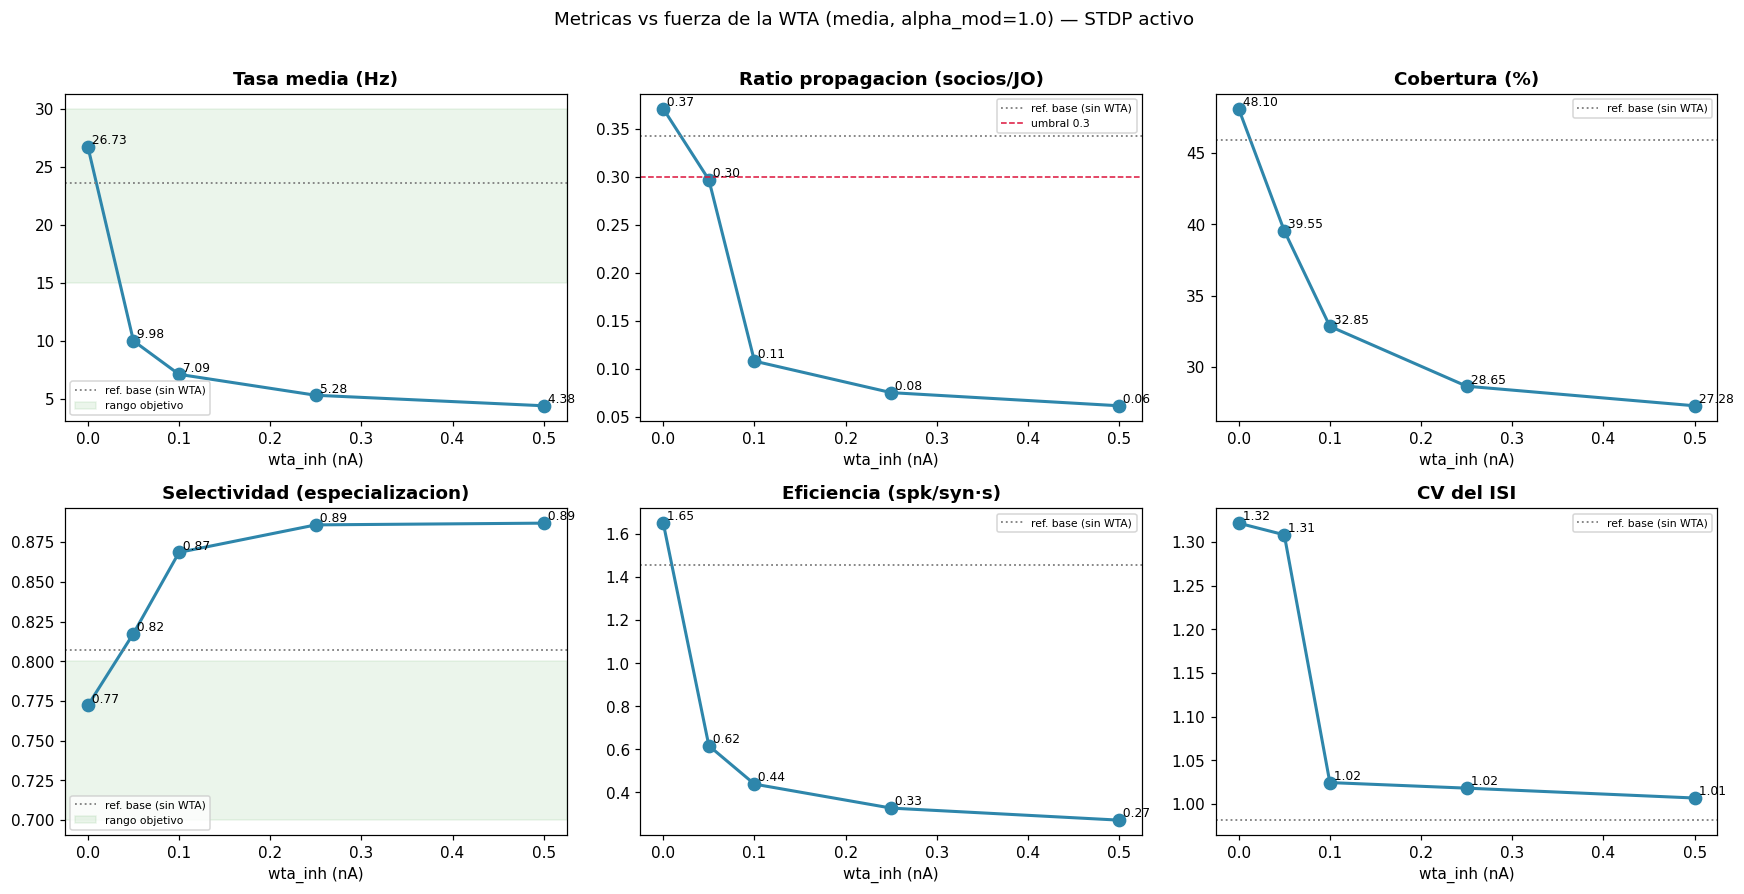

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
xs = WTA_VALS
panel = [('mean_rate_hz','Mean rate (Hz)', (15,30)),
         ('propagation_ratio','Propagation ratio (partners/JO)', None),
         ('coverage_pct','Coverage (%)', None),
         ('selectivity','Selectivity (specialization)', (0.7,0.8)),
         ('efficiency','Efficiency (spk/syn·s)', None),
         ('cv_isi','ISI CV', None)]
for a,(k,tit,band) in zip(ax.ravel(), panel):
    vals = [sweep[wi][k] for wi in WTA_VALS]
    a.plot(xs, vals, 'o-', color='#2E86AB', lw=2, ms=8)
    for x,v in zip(xs, vals): a.text(x, v, f' {v:.2f}', fontsize=8, va='bottom')
    a.axhline(ref_base[k], color='gray', ls=':', lw=1.2, label='baseline ref. (no WTA)')
    if k=='propagation_ratio': a.axhline(0.3, color='crimson', ls='--', lw=1, label='threshold 0.3')
    if band: a.axhspan(band[0], band[1], color='green', alpha=0.08, label='target range')
    a.set(title=tit, xlabel='wta_inh (nA)'); a.legend(fontsize=7)
fig.suptitle('Metrics vs WTA strength (mean, alpha_mod=1.0) — STDP on', y=1.01)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig01_metrics_vs_wta_inhibition.png'); plt.show()

### 4.2. The central trade-off, activity against specialization

WTA pulls two things in opposite directions. It lowers rate and propagation, switching the network off, while raising selectivity, which specializes it. This panel crosses the two so the balance point becomes visible.


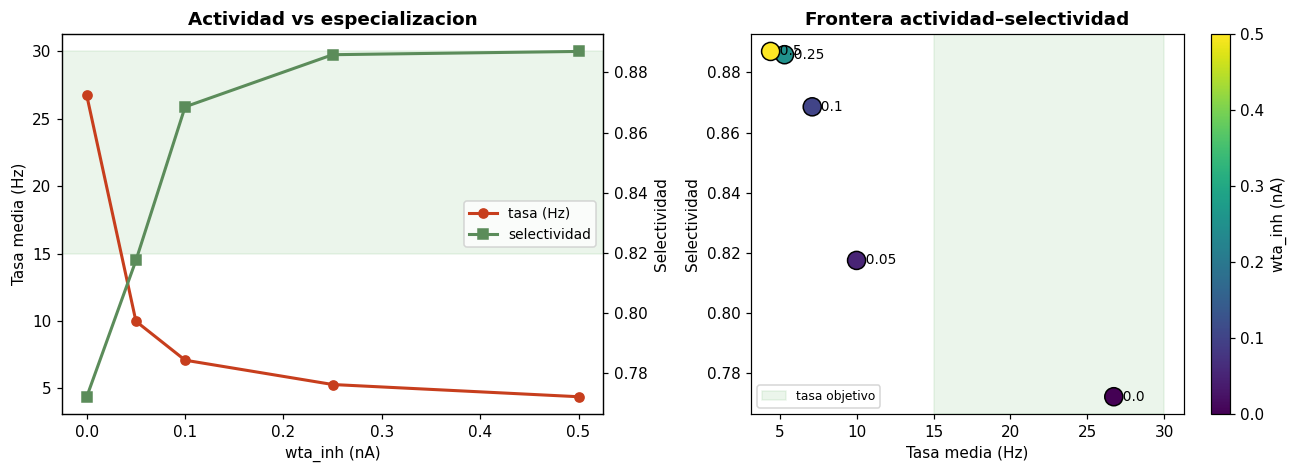

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
rate_v = [sweep[wi]['mean_rate_hz'] for wi in WTA_VALS]
ratio  = [sweep[wi]['propagation_ratio'] for wi in WTA_VALS]
selec  = [sweep[wi]['selectivity'] for wi in WTA_VALS]

ax0 = ax[0]; ax0b = ax0.twinx()
l1, = ax0.plot(WTA_VALS, rate_v, 'o-', color='#C73E1D', lw=2, label='rate (Hz)')
ax0.axhspan(15,30, color='green', alpha=0.08)
l2, = ax0b.plot(WTA_VALS, selec, 's-', color='#5B8C5A', lw=2, label='selectivity')
ax0.set(xlabel='wta_inh (nA)', ylabel='Mean rate (Hz)', title='Activity vs specialization')
ax0b.set_ylabel('Selectivity')
ax0.legend(handles=[l1,l2], loc='center right', fontsize=9)

# trade-off scatter: one point per wta_inh
sc = ax[1].scatter(rate_v, selec, c=WTA_VALS, cmap='viridis', s=140, edgecolor='k', zorder=3)
for wi,x,y in zip(WTA_VALS, rate_v, selec): ax[1].text(x, y, f'  {wi}', va='center', fontsize=9)
ax[1].axvspan(15,30, color='green', alpha=0.08, label='target rate')
ax[1].set(xlabel='Mean rate (Hz)', ylabel='Selectivity', title='Activity-selectivity frontier')
plt.colorbar(sc, ax=ax[1], label='wta_inh (nA)'); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig02_activity_selectivity_tradeoff.png'); plt.show()

### 4.3. Learning stability against `wta_inh`


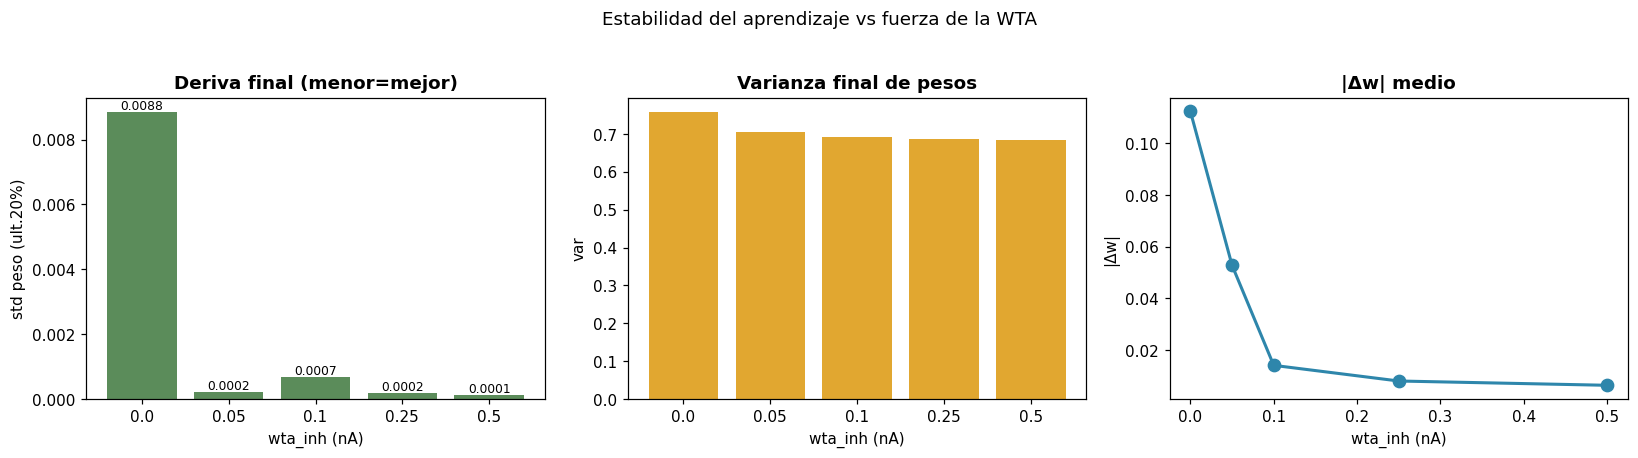

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
drift = [sweep[wi]['drift_final'] for wi in WTA_VALS]
var   = [sweep[wi]['w_var_final'] for wi in WTA_VALS]
dw    = [sweep[wi]['dw_abs_mean'] for wi in WTA_VALS]
ax[0].bar([str(w) for w in WTA_VALS], drift, color='#5B8C5A')
ax[0].set(title='Final drift (lower=better)', xlabel='wta_inh (nA)', ylabel='std of weight (last 20%)')
for i,v in enumerate(drift): ax[0].text(i, v, f'{v:.4f}', ha='center', va='bottom', fontsize=8)
ax[1].bar([str(w) for w in WTA_VALS], var, color='#E1A730')
ax[1].set(title='Final weight variance', xlabel='wta_inh (nA)', ylabel='var')
ax[2].plot(WTA_VALS, dw, 'o-', color='#2E86AB', lw=2, ms=8)
ax[2].set(title='Mean |Δw|', xlabel='wta_inh (nA)', ylabel='|Δw|')
fig.suptitle('Learning stability vs WTA strength', y=1.03)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig03_weight_stability.png'); plt.show()

### 4.4. Raster comparison, strong WTA against calibrated WTA

Here we look at the spatiotemporal structure at the extreme that shut the network down (`wta_inh=0.5`), at the middle point, and without competition (`wta_inh=0.0`).


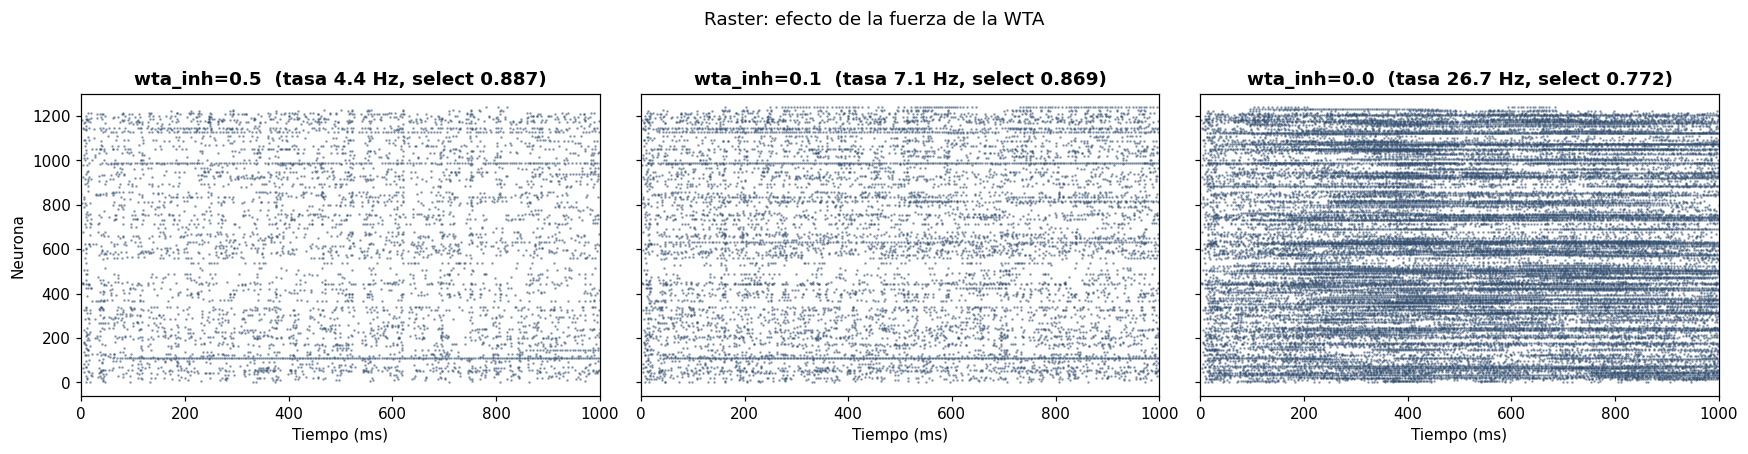

In [8]:
three = [0.5, 0.1, 0.0]
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
for a, wi in zip(ax, three):
    s = sweep[wi]
    a.scatter(s['t'], s['i'], s=0.4, c='#2E4A6B', alpha=0.5)
    a.set(title=f"wta_inh={wi}  (rate {s['mean_rate_hz']:.1f} Hz, select {s['selectivity']:.3f})",
          xlim=(0,1000), xlabel='Time (ms)')
ax[0].set_ylabel('Neuron')
fig.suptitle('Raster: effect of WTA strength', y=1.02)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig04_raster_comparison.png'); plt.show()

## 5. Full comparison table


In [9]:
rows = []
# baseline reference row
b = ref_base
rows.append({'wta_inh':'base(noWTA)', 'rate_Hz':round(b['mean_rate_hz'],2),
    'coverage_%':round(b['coverage_pct'],1), 'prop_ratio':round(b['propagation_ratio'],3),
    'selectivity':round(b['selectivity'],3), 'cv_isi':round(b['cv_isi'],3),
    'efficiency':round(b['efficiency'],3), 'var_final':'-', 'drift':'-'})
for wi in WTA_VALS:
    s = sweep[wi]
    rows.append({'wta_inh':wi, 'rate_Hz':round(s['mean_rate_hz'],2),
        'coverage_%':round(s['coverage_pct'],1), 'prop_ratio':round(s['propagation_ratio'],3),
        'selectivity':round(s['selectivity'],3), 'cv_isi':round(s['cv_isi'],3),
        'efficiency':round(s['efficiency'],3), 'var_final':round(s['w_var_final'],3),
        'drift':round(s['drift_final'],4)})
table = pd.DataFrame(rows).set_index('wta_inh')
table.to_csv(OUT_DIR/'table01_wta_calibration.csv')
print('Saved: table01_wta_calibration.csv')
table

Saved: table01_wta_calibration.csv


,tasa_Hz,cobertura_%,ratio_prop,selectiv,cv_isi,eficiencia,var_final,deriva
wta_inh,,,,,,,,
base(sinWTA),23.58,45.9,0.343,0.807,0.981,1.456,-,-
0.0,26.73,48.1,0.371,0.772,1.322,1.651,0.758,0.0088
0.05,9.98,39.5,0.297,0.817,1.308,0.616,0.706,0.0002
0.1,7.09,32.8,0.108,0.869,1.024,0.438,0.692,0.0007
0.25,5.28,28.7,0.075,0.886,1.018,0.326,0.687,0.0002
0.5,4.38,27.3,0.061,0.887,1.007,0.270,0.684,0.0001


## 6. What each metric means, a quick reminder

| Metric | In plain terms | Target |
|---|---|---|
| **Mean rate (Hz)** | spikes per neuron and second | 15–30 (neither off nor saturated) |
| **Coverage (%)** | % of neurons taking part | >40 |
| **Propagation ratio** | signal reaching AMMC from JO | >0.3 |
| **Selectivity** | specialization (sparseness) | 0.7–0.8, this is what WTA contributes |
| **Efficiency (spk/syn·s)** | energy cost (proxy) | lower is better |
| **ISI CV** | how regular the firing is | ~1 is natural |
| **Variance / drift** | spread and stability of the weights | lower means stable convergence |

`wta_inh` is the strength of the lateral inhibition, the knob that sets the trade-off between activity and specialization.


## 7. Reading the results, and a recommendation

*(Values from the table in section 5 and from the figures.)*

### 7.1. The trade-off is real, and very abrupt
| wta_inh | rate Hz | prop ratio | selectivity | drift | reading |
|---|---|---|---|---|---|
| baseline (no WTA, no STDP) | 23.58 | 0.343 | 0.807 | — | dynamic ceiling |
| **0.0** (STDP, no competition) | **26.73** | **0.371** | 0.772 | **0.0088** | active and propagating, but **unstable** and less selective |
| **0.05** | 9.98 | 0.297 | **0.817** | 0.0002 | selective and stable, though the rate already falls under 15 |
| 0.1 | 7.09 | 0.108 | 0.869 | 0.0007 | going quiet |
| 0.25 | 5.28 | 0.075 | 0.886 | 0.0002 | off |
| 0.5 (previous value) | 4.38 | 0.061 | 0.887 | 0.0001 | off, the original problem |

Between `wta_inh = 0.0` and `0.05` the rate collapses from 26.7 to 10 Hz. The global WTA, 50 inhibitory neurons onto all N, is strongly non-linear, with nearly all of its effect packed into that first stretch.

### 7.2. Did it improve? Partly
- Lowering `wta_inh` from 0.5 to 0.05 brings the network back to life (4.38 to 9.98 Hz) and recovers the propagation ratio from 0.061 to **0.297**, almost at the 0.3 threshold, while keeping selectivity high at 0.817 and drift at 0.0002. A clear improvement over 0.5.
- The full window was not reached, though. No single value gives rate in 15–30 *and* ratio above 0.3 *and* selectivity *and* stability at once. At `wta_inh=0.0` the rate and ratio are good but learning is unstable (drift 0.0088) and selectivity drops. At `wta_inh=0.05` learning is stable and selective, but the rate hovers around 10 Hz.
- Watch out for the high selectivity at large `wta_inh` (0.87–0.89). That is trivial sparseness, high only because almost nobody fires, not because anything useful was learned.

### 7.3. Best point so far, and what comes next
- The best point is `wta_inh ≈ 0.05`. It brings the network back, stays selective and stable, and puts the ratio right at the limit.
- The optimum lies between 0.0 and 0.05, so the next step is a finer sweep over `{0.01, 0.02, 0.03, 0.04}`.
- There is also a structural alternative. The current WTA is dense, everyone inhibiting everyone. A sparse WTA, with local lateral inhibition, would soften the trade-off and would probably open the full window.

**Conclusion.** Calibration improves on the inherited 0.5, but the global design of the WTA imposes a trade-off that is too sharp. Before classification, two things: a fine sweep, and an evaluation of locally connected WTA.


---

# Continuation — fine sweep and sparse WTA

The first part showed that the best point of the **dense** WTA sat at `wta_inh ≈ 0.05`, with a very abrupt trade-off, and that the real optimum seemed to fall between 0.0 and 0.05. Two things follow from that.

1. A **fine sweep** of `wta_inh ∈ {0.01, 0.02, 0.03, 0.04}` on the dense WTA, to pin down the exact point.
2. A **sparse WTA** with local rather than global lateral inhibition. Instead of every inhibitory neuron braking all the others, it brakes only a fraction `wta_p` of the network. Our hypothesis is that this softens the trade-off and allows competition without switching the network off.

## 8. Fine sweep of `wta_inh` (dense WTA)


In [10]:
FINE_VALS = [0.01, 0.02, 0.03, 0.04]
fine = {}
for wi in FINE_VALS:
    s = simulate(wi, with_stdp=True, wta_p=1.0)
    fine[wi] = s
    print(f'wta_inh={wi:>4} -> rate {s["mean_rate_hz"]:5.2f} Hz | prop_ratio {s["propagation_ratio"]:.3f} '
          f'| coverage {s["coverage_pct"]:4.1f}% | selectivity {s["selectivity"]:.3f} | drift {s["drift_final"]:.4f}')

WARNING    'i' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value 4. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'v' is an internal variable of group 'neurongroup_3', but also exists in the run namespace with the value 0.00012130916479953884. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'v' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value 0.00012130916479953884. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'v' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value 0.00012130916479953884. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'v' is an internal variable of group 'neurongroup_2', but also exists in the run namespace with the value 0.00012130916479953884. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


wta_inh=0.01 -> rate 17.32 Hz | prop_ratio 0.289 | coverage 42.9% | selectivity 0.830 | drift 0.0054


wta_inh=0.02 -> rate 14.41 Hz | prop_ratio 0.344 | coverage 43.1% | selectivity 0.803 | drift 0.0028


wta_inh=0.03 -> rate 12.76 Hz | prop_ratio 0.312 | coverage 41.1% | selectivity 0.833 | drift 0.0005


wta_inh=0.04 -> rate 11.93 Hz | prop_ratio 0.473 | coverage 40.0% | selectivity 0.854 | drift 0.0128


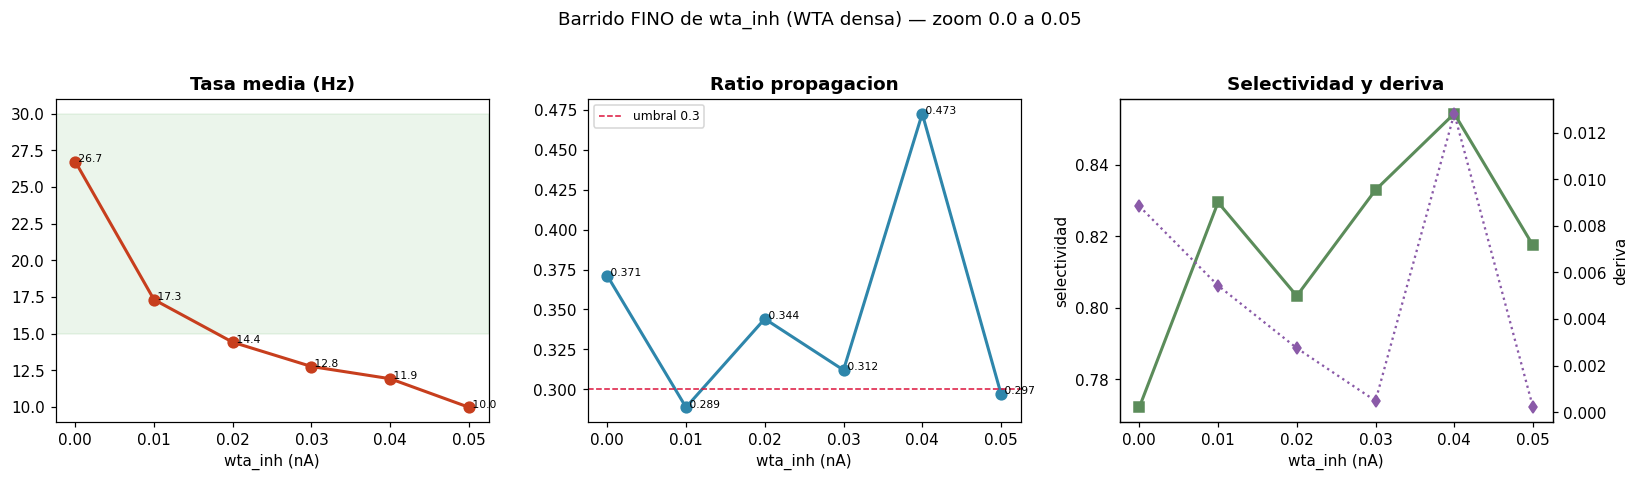

In [11]:
# Combine with the already known ends (0.0 and 0.05) to see the whole curve
COMB = [0.0] + FINE_VALS + [0.05]
def get(wi):
    if wi in fine: return fine[wi]
    return sweep[wi]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
rate_v = [get(w)['mean_rate_hz'] for w in COMB]
ratio  = [get(w)['propagation_ratio'] for w in COMB]
selec  = [get(w)['selectivity'] for w in COMB]
drift  = [get(w)['drift_final'] for w in COMB]
ax[0].plot(COMB, rate_v, 'o-', color='#C73E1D', lw=2, ms=7); ax[0].axhspan(15,30,color='green',alpha=0.08)
ax[0].set(title='Mean rate (Hz)', xlabel='wta_inh (nA)')
for x,v in zip(COMB,rate_v): ax[0].text(x,v,f' {v:.1f}',fontsize=7)
ax[1].plot(COMB, ratio, 'o-', color='#2E86AB', lw=2, ms=7); ax[1].axhline(0.3,color='crimson',ls='--',lw=1,label='threshold 0.3')
ax[1].set(title='Propagation ratio', xlabel='wta_inh (nA)'); ax[1].legend(fontsize=8)
for x,v in zip(COMB,ratio): ax[1].text(x,v,f' {v:.3f}',fontsize=7)
ax[2].plot(COMB, selec, 's-', color='#5B8C5A', lw=2, ms=7, label='selectivity')
axb=ax[2].twinx(); axb.plot(COMB, drift, 'd:', color='#8A5AA8', lw=1.5, label='drift')
ax[2].set(title='Selectivity and drift', xlabel='wta_inh (nA)'); ax[2].set_ylabel('selectivity'); axb.set_ylabel('drift')
fig.suptitle('FINE sweep of wta_inh (dense WTA) — zoom 0.0 to 0.05', y=1.03)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig05_fine_sweep.png'); plt.show()

## 9. Sparse WTA (local lateral inhibition)

The dense WTA switches the network off because every inhibitory neuron brakes the entire network, so suppression is global and massive. A sparse WTA connects `G_inh → G` only with probability `wta_p`, so 0.1 means each inhibitory neuron brakes a randomly chosen 10 % of the network. Competition then becomes local: enough inhibition to specialize, not enough to silence everything.

With fewer lateral synapses we can afford a higher `wta_inh` per synapse without collapsing the network. We test `wta_p ∈ {0.1, 0.25}` against `wta_inh ∈ {0.1, 0.25, 0.5}` and compare with the dense case.


In [12]:
P_VALS  = [0.1, 0.25]
WI_SPARSE = [0.1, 0.25, 0.5]
sparse = {}
for p in P_VALS:
    for wi in WI_SPARSE:
        s = simulate(wi, with_stdp=True, wta_p=p)
        sparse[(p,wi)] = s
        print(f'wta_p={p} wta_inh={wi:>4} -> n_lat {s["n_lat"]:>6,} | rate {s["mean_rate_hz"]:5.2f} Hz '
              f'| prop_ratio {s["propagation_ratio"]:.3f} | coverage {s["coverage_pct"]:4.1f}% '
              f'| selectivity {s["selectivity"]:.3f} | drift {s["drift_final"]:.4f}')
print(f'\n(reference: dense WTA n_lat = {sweep[0.5]["n_lat"]:,})')

WARNING    'v' is an internal variable of group 'neurongroup_3', but also exists in the run namespace with the value 0.2971148530996932. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'v' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value 0.2971148530996932. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'v' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value 0.2971148530996932. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'v' is an internal variable of group 'neurongroup_2', but also exists in the run namespace with the value 0.2971148530996932. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


wta_p=0.1 wta_inh= 0.1 -> n_lat  6,133 | rate 20.38 Hz | prop_ratio 0.444 | coverage 43.9% | selectivity 0.815 | drift 0.0088


wta_p=0.1 wta_inh=0.25 -> n_lat  6,133 | rate 14.38 Hz | prop_ratio 0.388 | coverage 40.8% | selectivity 0.839 | drift 0.0011


wta_p=0.1 wta_inh= 0.5 -> n_lat  6,133 | rate  9.69 Hz | prop_ratio 0.200 | coverage 38.3% | selectivity 0.817 | drift 0.0061


wta_p=0.25 wta_inh= 0.1 -> n_lat 15,429 | rate 15.87 Hz | prop_ratio 0.645 | coverage 40.2% | selectivity 0.869 | drift 0.0018


wta_p=0.25 wta_inh=0.25 -> n_lat 15,429 | rate  8.82 Hz | prop_ratio 0.218 | coverage 38.2% | selectivity 0.812 | drift 0.0003


wta_p=0.25 wta_inh= 0.5 -> n_lat 15,429 | rate  6.68 Hz | prop_ratio 0.110 | coverage 32.9% | selectivity 0.845 | drift 0.0012

(reference: dense WTA n_lat = 61,950)


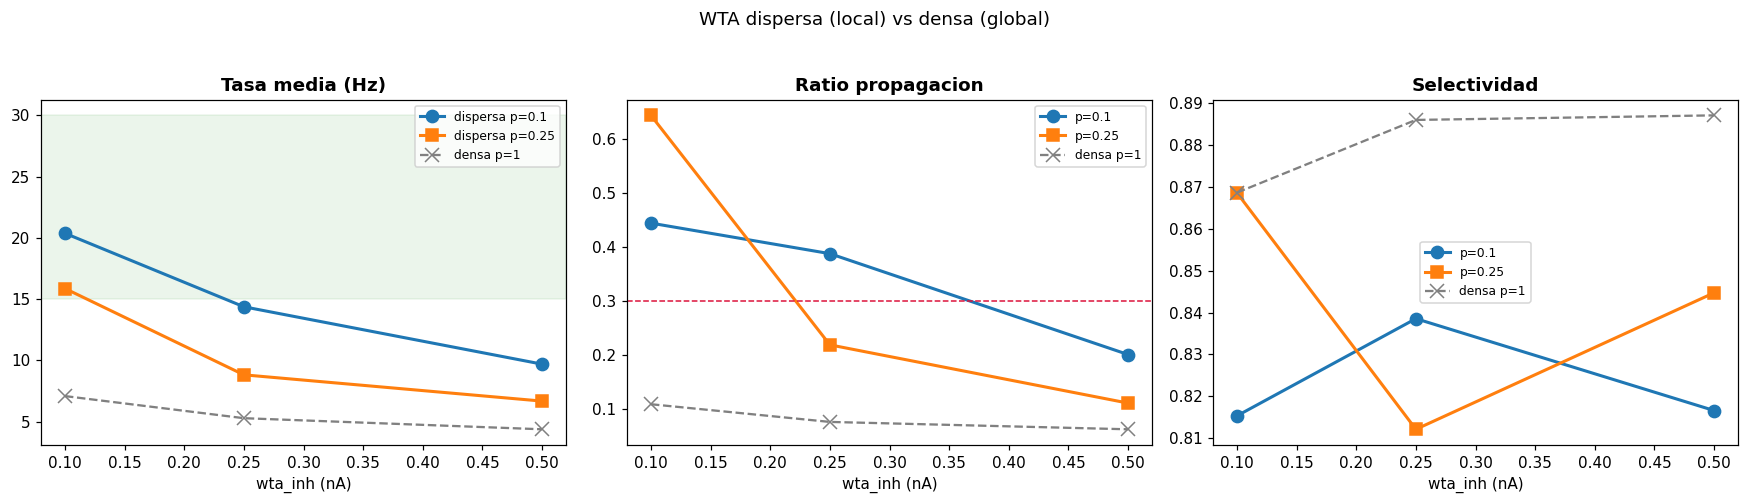

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
markers = {0.1:'o', 0.25:'s'}
for p in P_VALS:
    xs = WI_SPARSE
    ax[0].plot(xs, [sparse[(p,wi)]['mean_rate_hz'] for wi in xs], markers[p]+'-', lw=2, ms=8, label=f'sparse p={p}')
    ax[1].plot(xs, [sparse[(p,wi)]['propagation_ratio'] for wi in xs], markers[p]+'-', lw=2, ms=8, label=f'p={p}')
    ax[2].plot(xs, [sparse[(p,wi)]['selectivity'] for wi in xs], markers[p]+'-', lw=2, ms=8, label=f'p={p}')
# dense case as reference (p=1) at the same wta_inh values
ax[0].plot(WI_SPARSE, [sweep[wi]['mean_rate_hz'] for wi in WI_SPARSE], 'x--', color='gray', lw=1.5, ms=9, label='dense p=1')
ax[1].plot(WI_SPARSE, [sweep[wi]['propagation_ratio'] for wi in WI_SPARSE], 'x--', color='gray', lw=1.5, ms=9, label='dense p=1')
ax[2].plot(WI_SPARSE, [sweep[wi]['selectivity'] for wi in WI_SPARSE], 'x--', color='gray', lw=1.5, ms=9, label='dense p=1')
ax[0].axhspan(15,30,color='green',alpha=0.08); ax[0].set(title='Mean rate (Hz)', xlabel='wta_inh (nA)'); ax[0].legend(fontsize=8)
ax[1].axhline(0.3,color='crimson',ls='--',lw=1); ax[1].set(title='Propagation ratio', xlabel='wta_inh (nA)'); ax[1].legend(fontsize=8)
ax[2].set(title='Selectivity', xlabel='wta_inh (nA)'); ax[2].legend(fontsize=8)
fig.suptitle('Sparse WTA (local) vs dense WTA (global)', y=1.03)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig06_dense_vs_sparse_wta.png'); plt.show()

## 10. Final table (fine sweep plus sparse WTA) and conclusion


In [14]:
rows = []
for wi in [0.0, 0.01, 0.02, 0.03, 0.04, 0.05]:
    s = get(wi)
    rows.append({'config':f'dense wi={wi}', 'wta_p':1.0, 'n_lat':s.get('n_lat','-'),
        'rate_Hz':round(s['mean_rate_hz'],2), 'prop_ratio':round(s['propagation_ratio'],3),
        'coverage_%':round(s['coverage_pct'],1), 'selectivity':round(s['selectivity'],3),
        'drift':round(s['drift_final'],4)})
for p in P_VALS:
    for wi in WI_SPARSE:
        s = sparse[(p,wi)]
        rows.append({'config':f'sparse p={p} wi={wi}', 'wta_p':p, 'n_lat':s['n_lat'],
            'rate_Hz':round(s['mean_rate_hz'],2), 'prop_ratio':round(s['propagation_ratio'],3),
            'coverage_%':round(s['coverage_pct'],1), 'selectivity':round(s['selectivity'],3),
            'drift':round(s['drift_final'],4)})
table2 = pd.DataFrame(rows).set_index('config')
table2.to_csv(OUT_DIR/'table02_fine_sweep_and_sparse.csv')
print('Saved: table02_fine_sweep_and_sparse.csv')
table2

Saved: table02_fine_sweep_and_sparse.csv


,wta_p,n_lat,tasa_Hz,ratio_prop,cobertura_%,selectiv,deriva
config,,,,,,,
densa wi=0.0,1.00,61950,26.73,0.371,48.1,0.772,0.0088
densa wi=0.01,1.00,61950,17.32,0.289,42.9,0.830,0.0054
densa wi=0.02,1.00,61950,14.41,0.344,43.1,0.803,0.0028
densa wi=0.03,1.00,61950,12.76,0.312,41.1,0.833,0.0005
densa wi=0.04,1.00,61950,11.93,0.473,40.0,0.854,0.0128
densa wi=0.05,1.00,61950,9.98,0.297,39.5,0.817,0.0002
dispersa p=0.1 wi=0.1,0.10,6133,20.38,0.444,43.9,0.815,0.0088
dispersa p=0.1 wi=0.25,0.10,6133,14.38,0.388,40.8,0.839,0.0011
dispersa p=0.1 wi=0.5,0.10,6133,9.69,0.200,38.3,0.817,0.0061


## 11. Reading the continuation

*(Values from the table in section 10 and from figures 05 and 06.)*

### 11.1. Fine sweep on the dense WTA, where 0.02 is confirmed
| wta_inh | rate Hz | prop ratio | selectivity | drift | verdict |
|---|---|---|---|---|---|
| 0.0 | 26.73 | 0.371 | 0.772 | 0.0088 | unstable |
| 0.01 | 17.32 | 0.289 | 0.830 | 0.0054 | ratio under the threshold |
| **0.02** | **14.41** | **0.344** | **0.803** | 0.0028 | **best dense point**: rate almost in range, ratio above 0.3, stable |
| 0.03 | 12.76 | 0.312 | 0.833 | 0.0005 | very stable, rate already low |
| 0.04 | 11.93 | 0.473 | 0.854 | 0.0128 | high ratio, but noisy drift |
| 0.05 | 9.98 | 0.297 | 0.817 | 0.0002 | going quiet |

Within the dense WTA, `wta_inh ≈ 0.02` is the best point, with rate 14.4 Hz at the edge of the range, ratio 0.344, selectivity 0.803 and stable learning. The rate still sits just below 15 Hz, so the dense design never quite clears the ceiling that the trade-off imposes.

### 11.2. Sparse WTA opens the full window, and this is the main finding
| config | n_lat | rate Hz | prop ratio | coverage | selectivity | drift |
|---|---|---|---|---|---|---|
| dense 0.02 (best dense) | 61 950 | 14.41 | 0.344 | 43.1 | 0.803 | 0.0028 |
| **sparse p=0.25, wi=0.1** | **15 429** | **15.87** | **0.645** | 40.2 | **0.869** | **0.0018** |
| sparse p=0.1, wi=0.1 | 6 133 | 20.38 | 0.444 | 43.9 | 0.815 | 0.0088 |

`sparse p=0.25, wi=0.1` meets all four conditions at the same time, and with room to spare. Rate 15.87 Hz, inside the 15–30 range. Propagation ratio 0.645, more than double the 0.3 threshold. Coverage 40.2 %, selectivity 0.869, drift 0.0018. It also uses four times fewer lateral synapses than the dense version (15 429 against 61 950), which makes it cheaper.

Local inhibition breaks a trade-off that global inhibition could not. With few lateral connections but heavier weights, there is enough competition to specialize (selectivity 0.87) without the massive suppression that shut the network down. In figure 06 the sparse curves sit well above the dense grey line in rate and propagation, at the same selectivity.

### 11.3. Final recommendation
- **Chosen configuration: mean + `alpha_mod=1.0` + sparse WTA with `wta_p=0.25`, `wta_inh=0.1`.** It is the only one meeting the four target metrics simultaneously, and it costs less than the dense version.
- An ultra-cheap alternative for edge AI is `wta_p=0.1`, `wta_inh=0.1`, with only 6 133 lateral synapses, rate 20.4 Hz and ratio 0.444, at the price of somewhat larger drift (0.0088).
- Compared with the whole earlier series the gain is clear. We went from a network that was off (4.4 Hz, ratio 0.06 under the dense WTA at 0.5) to one that is alive, propagating, specialized and stable. Ready for the auditory classification phase.
